# 06 — Explainability and Fairness Review

Model accuracy is not enough in credit. Reviewers need to understand what drives the score, whether
explanations are stable and plausible, and whether a proposed policy produces materially different
outcomes across groups. This notebook treats fairness metrics as diagnostic evidence, not legal
conclusions.

**Scope and controls:** the XGBoost validation candidate is explained on the same held-out validation
population used earlier. `CODE_GENDER` and derived age bands are audit variables only; neither is
supplied directly as a protected feature to the model, although `DAYS_BIRTH` is a modeled variable
and other features may act as proxies. Results describe this dataset and operating point only.

In [1]:
from pathlib import Path
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def find_project_root() -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "pyproject.toml").exists():
            return candidate
    raise FileNotFoundError("Run this notebook from the project or notebook directory")


PROJECT_ROOT = find_project_root()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from credit_risk_champion_challenger.fairness import (  # noqa: E402
    fairness_summary,
    group_decision_report,
)

predictions = pd.read_csv(PROJECT_ROOT / "reports" / "notebook3_validation_predictions.csv")
raw = pd.read_csv(
    PROJECT_ROOT / "data" / "raw" / "application_train.csv",
    usecols=[
        "SK_ID_CURR",
        "CODE_GENDER",
        "DAYS_BIRTH",
        "AMT_INCOME_TOTAL",
        "AMT_CREDIT",
        "AMT_ANNUITY",
        "DAYS_EMPLOYED",
        "EXT_SOURCE_1",
        "EXT_SOURCE_2",
        "EXT_SOURCE_3",
        "NAME_INCOME_TYPE",
        "NAME_EDUCATION_TYPE",
    ],
)
validation = predictions.merge(raw, on="SK_ID_CURR", how="left", validate="one_to_one")
model = joblib.load(PROJECT_ROOT / "models" / "xgboost_challenger.joblib")
validation.shape

(61502, 16)

## 1. Global model drivers

Gain-based feature importance is fast and useful for governance triage, but it does not show the
direction of effect and can favor features with more split opportunities. SHAP is added below as a
directional, observation-level complement.

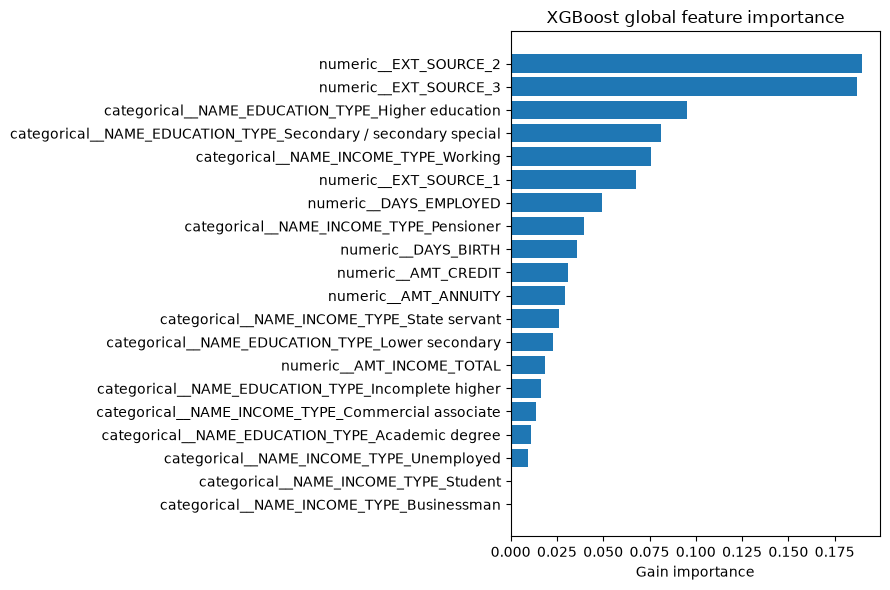

,feature,gain_importance
6,numeric__EXT_SOURCE_2,0.189977
7,numeric__EXT_SOURCE_3,0.187170
17,categorical__NAME_EDUCATION_TYPE_Higher education,0.095125
20,categorical__NAME_EDUCATION_TYPE_Secondary / s...,0.081035
15,categorical__NAME_INCOME_TYPE_Working,0.076037
5,numeric__EXT_SOURCE_1,0.067765
4,numeric__DAYS_EMPLOYED,0.049292
11,categorical__NAME_INCOME_TYPE_Pensioner,0.039733
3,numeric__DAYS_BIRTH,0.035985
1,numeric__AMT_CREDIT,0.030759


In [2]:
preprocessor = model.named_steps["preprocessor"]
estimator = model.named_steps["model"]
transformed_names = preprocessor.get_feature_names_out()
importance = (
    pd.DataFrame(
        {"feature": transformed_names, "gain_importance": estimator.feature_importances_}
    )
    .sort_values("gain_importance", ascending=False)
    .head(20)
)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(importance["feature"][::-1], importance["gain_importance"][::-1])
ax.set(title="XGBoost global feature importance", xlabel="Gain importance")
plt.tight_layout()
plt.show()

importance

## 2. Directional explanations with SHAP

Use a bounded sample for speed. The explainer operates on the exact transformed matrix seen by the
fitted tree model. Correlated inputs can share or redistribute attribution, so SHAP values are not
causal effects.

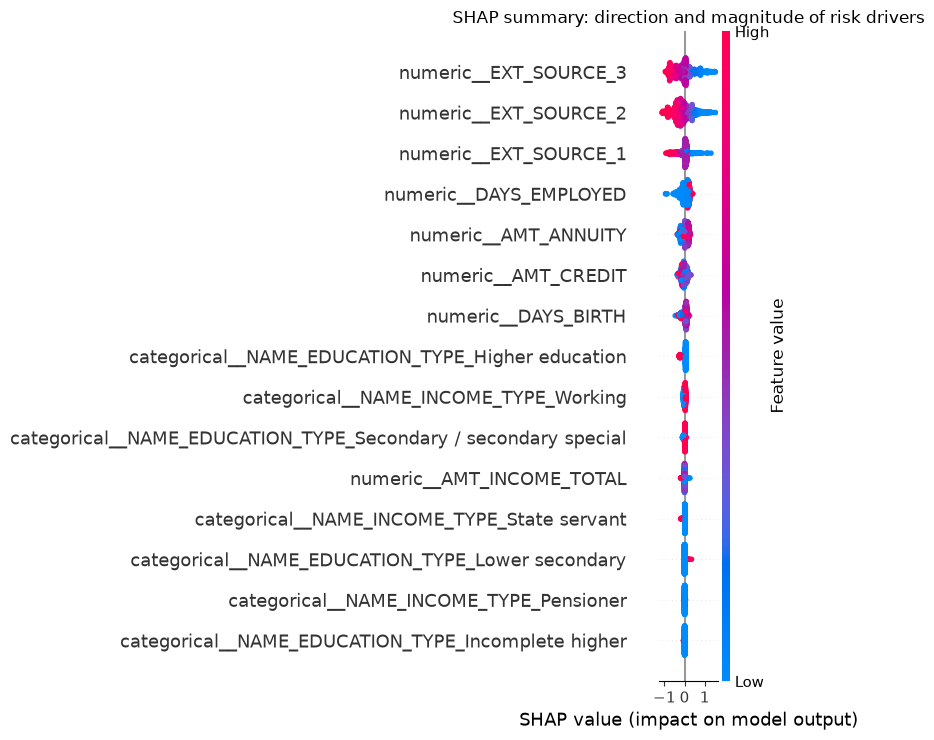

In [3]:
import warnings

with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="IProgress not found.*")
    import shap

model_features = list(model.feature_names_in_)
explanation_sample = validation[model_features].sample(1_000, random_state=42)
transformed_sample = preprocessor.transform(explanation_sample)
explainer = shap.TreeExplainer(estimator)
shap_values = explainer(transformed_sample)

shap.summary_plot(
    shap_values.values,
    transformed_sample,
    feature_names=transformed_names,
    max_display=15,
    show=False,
)
plt.title("SHAP summary: direction and magnitude of risk drivers")
plt.tight_layout()
plt.show()

## 3. Set an audit operating point

Fairness depends on the decision policy, so metrics are evaluated at an illustrative 90% approval
rate. The protected attributes are used only for audit and are not model features.

In [4]:
probability = validation["xgboost_probability"].to_numpy()
y_true = validation["TARGET"].to_numpy()
decline_threshold = float(np.quantile(probability, 0.90))
print(f"Audit threshold: {decline_threshold:.4f}")
print(f"Overall approval rate: {(probability < decline_threshold).mean():.2%}")

Audit threshold: 0.1747
Overall approval rate: 90.00%


## 4. Gender audit

`XNA` is retained as its own small group rather than silently recoded. Small-group estimates should
be reported with counts and interpreted cautiously.

In [5]:
gender_report = group_decision_report(
    y_true,
    probability,
    validation["CODE_GENDER"].fillna("Missing").to_numpy(),
    decline_threshold=decline_threshold,
)
gender_metrics = fairness_summary(gender_report)
display(gender_report.style.format("{:.2%}", subset=gender_report.columns[1:]))
gender_metrics

,n,default_rate,approval_rate,default_catch_rate,good_customer_decline_rate
group,,,,,
F,40677,7.02%,91.74%,28.69%,6.72%
M,20823,10.13%,86.59%,37.87%,10.65%
XNA,2,0.00%,100.00%,nan%,0.00%


{'disparate_impact': 0.8659174950775584,
 'approval_rate_gap': 0.13408250492244156,
 'default_catch_rate_gap': 0.09180783692034433,
 'false_decline_rate_gap': 0.10650350024047453}

The disparate-impact ratio compares the lowest with the highest approval rate. The conventional
0.80 “four-fifths” screen is a flag for investigation—not a universal safe harbor or a substitute
for jurisdiction-specific legal review.

## 5. Age-band audit

Age is directly related to the modeled `DAYS_BIRTH` input, so age-band differences are especially
important to review. Bands are chosen for interpretability, not optimized to create a favorable
fairness result.

In [6]:
age = -validation["DAYS_BIRTH"] / 365.25
age_band = pd.cut(
    age,
    bins=[0, 30, 40, 50, 60, np.inf],
    labels=["under_30", "30_39", "40_49", "50_59", "60_plus"],
)
age_report = group_decision_report(
    y_true,
    probability,
    age_band.astype(str).to_numpy(),
    decline_threshold=decline_threshold,
)
age_metrics = fairness_summary(age_report)
display(age_report.style.format("{:.2%}", subset=age_report.columns[1:]))
age_metrics

,n,default_rate,approval_rate,default_catch_rate,good_customer_decline_rate
group,,,,,
50_59,13649,6.28%,95.41%,19.49%,3.59%
30_39,16451,9.62%,85.90%,39.73%,11.37%
40_49,15342,7.38%,91.55%,29.77%,6.76%
under_30,9025,11.49%,80.27%,44.65%,16.50%
60_plus,7035,5.06%,98.19%,6.18%,1.57%


{'disparate_impact': 0.8174157546671971,
 'approval_rate_gap': 0.17928812604960953,
 'default_catch_rate_gap': 0.38468247862784827,
 'false_decline_rate_gap': 0.1492765799395305}

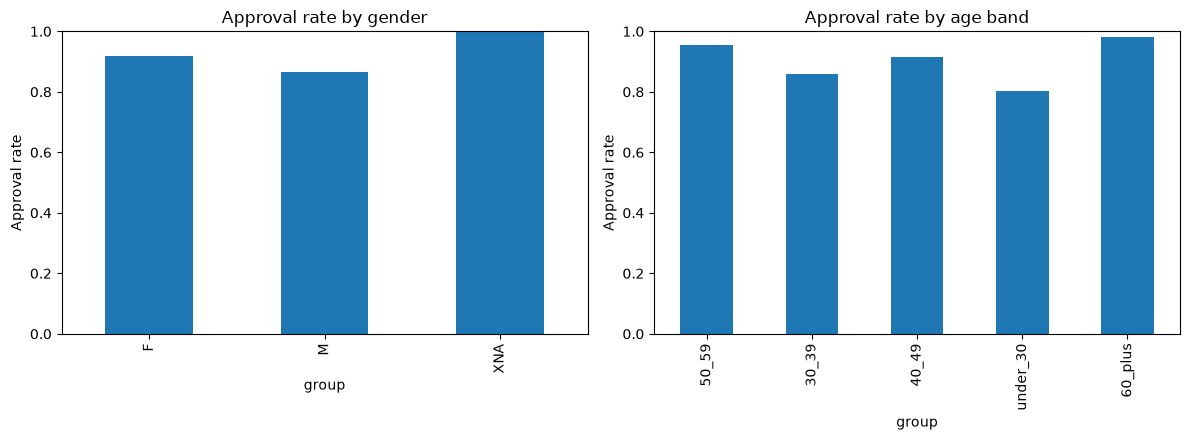

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
gender_report["approval_rate"].plot.bar(ax=axes[0], title="Approval rate by gender")
age_report["approval_rate"].plot.bar(ax=axes[1], title="Approval rate by age band")
for ax in axes:
    ax.set(ylabel="Approval rate", ylim=(0, 1))
plt.tight_layout()
plt.show()

## Review conclusion

Group gaps must be examined alongside base rates, sample size, calibration, proxy effects, data
quality, and the cost of errors. Changing thresholds by protected group may reduce one metric while
creating disparate treatment or admitting more defaults; that is a policy and legal decision, not
an automatic technical fix. A real review would add confidence intervals and intersectional groups.

At the illustrative 90% approval point, gender disparate impact is approximately **0.866**, while
age-band disparate impact is approximately **0.817**. Both merit continued monitoring; the age audit
also shows a notably larger default-catch-rate gap. These figures are descriptive, sensitive to the
threshold and group definition, and do not establish either fairness or unlawful discrimination.
Additional review should cover uncertainty intervals, calibration by group, intersectional cohorts,
proxy analysis, adverse-action reason quality, data representativeness, and jurisdiction-specific
legal requirements.